In [1]:
import os
import pandas as pd
from topictools import prepare_mallet_data

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
data_dir = "/Users/jeriwieringa/Dissertation/data/"

In [4]:
model = prepare_mallet_data.MalletModel(os.path.join(data_dir, 
                                                     'model_outputs', 
                                                     'target_300_10.18497.state.gz'
                                                    ))

In [5]:
df = model.model()

In [6]:
params = model.extract_params()

In [7]:
# Load metadata

metadata = pd.read_csv(os.path.join(data_dir, "corpus_metadata", "meta.csv"), header=None)\
            .reset_index()
metadata.columns = ['doc_id', 'filename', 'citation', 'author', 
                    'periodical_name', 'volume', 'issue', 
                    'date', 'page', 'url','abrev']
metadata['date_formatted'] = pd.to_datetime(metadata['date'])

In [8]:
# Load Labels

import gspread
from oauth2client.service_account import ServiceAccountCredentials

# Load data from Google Doc
scope = ['https://spreadsheets.google.com/feeds']
secrets = "/Users/jeriwieringa/Dissertation/dev/code/secrets/dissertation-881847769b13.json"
credentials = ServiceAccountCredentials.from_json_keyfile_name(secrets, scope)
gc = gspread.authorize(credentials)
dts = gc.open('Topic Labels').sheet1

labels = pd.DataFrame(dts.get_all_records())

In [9]:
doc_topic = df.groupby(['#doc', 'topic'])['type'].count().reset_index(name="token_count")

In [10]:
dt = doc_topic.merge(metadata, how='left', left_on="#doc", right_on="doc_id")

In [11]:
y_dt = dt.groupby([dt.date_formatted.dt.year, "topic"])['token_count']\
        .sum()\
        .reset_index(name='token_count')

In [12]:
y_m = prepare_mallet_data.pivot_smooth_norm(y_dt, params[0],
                                            'date_formatted', 'topic', 'token_count')

In [13]:
y_m[:2]

topic,0,1,2,3,4,5,6,7,8,9,...,240,241,242,243,244,245,246,247,248,249
date_formatted,,,,,,,,,,,,,,,,,,,,,
1849,0.000466,0.002586,0.001395,0.003516,0.010145,0.004582,0.001459,0.007097,0.000664,6.630487e-07,...,0.000995,0.000532,0.000067,0.000334,7.931035e-07,8.578557e-07,0.000001,0.000001,0.000200,7.317510e-07
1850,0.000748,0.000168,0.017215,0.002281,0.017356,0.010193,0.004587,0.017163,0.001495,1.032088e-04,...,0.004613,0.002564,0.001134,0.000954,5.169408e-05,6.459166e-05,0.000142,0.000155,0.000116,3.093819e-04


In [14]:
y_topics = y_m.unstack().reset_index(name='t_proportion')

Add metadata back and aggregate by labels

In [15]:
category_df = y_topics.merge(labels, how="left", left_on="topic", right_on="mallet_topic_id")\
[['topic', 'date_formatted', 't_proportion', 'topic_category', 'topic_label']]\
.groupby(['date_formatted', 'topic_category'])['t_proportion']\
.sum().reset_index(name='category_prevalence')

In [16]:
category_df[:35]

,date_formatted,topic_category,category_prevalence
0,1849,advertisements,0.006380
1,1849,apologetics,0.025667
2,1849,bible,0.145878
3,1849,church_and_state,0.002725
4,1849,community_news,0.000069
5,1849,conference_proceedings,0.000665
6,1849,correspondence,0.050922
7,1849,education,0.005384
8,1849,eschatology,0.129428
9,1849,general_interest,0.000670


Chart gives us an overview of the make up of the periodical literature in a given year. These numbers seem reasonable given my reading of these periodical documents.

## Browse Top Topics by Year

Interface for viewing the top 25 topics in each year. Select starting and ending year (both included in the displayed data.) Also includes an interactive chart of the top weights over time.

In [17]:
import plotly.graph_objs as go
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import cufflinks as cf

# Keep charts from syncing with Plotly servers.
init_notebook_mode(connected=True)
cf.go_offline()

In [18]:
years = category_df['date_formatted'].unique().tolist()

def get_top_values(df, n_top):
    return df.groupby('date_formatted').apply(lambda x: x.nlargest(n_top, 'category_prevalence'))\
    .reset_index(drop=True)
    
frame = get_top_values(category_df, 5)

In [19]:
frame[:5]

,date_formatted,topic_category,category_prevalence
0,1849,theology_sabbath,0.250820
1,1849,bible,0.145878
2,1849,eschatology,0.129428
3,1849,theology,0.123143
4,1849,correspondence,0.050922


In [20]:
# Function for generating chart data for different time periods
def top_topics(start_year='', end_year='', width=800, height=800):
    topics = frame[(frame['date_formatted'] >= start_year) & (frame['date_formatted'] <= end_year)]

    layout1 = go.Layout(
        height=height,
        width=width,
        yaxis=go.layout.YAxis(
#             title='Y-axis Title',
            automargin=True,
#             titlefont=dict(size=30),
        ),
    )
#     #Colors list create with http://tools.medialab.sciences-po.fr/iwanthue/
#     topic_colors = ["#c26933",
#                     "#557ee1",
#                     "#bca63a",
#                     "#9776d6",
#                     "#73a343",
#                     "#534894",
#                     "#54b06c",
#                     "#ba556d",
#                     "#64b694",
#                     "#b65147",
#                     "#5bbcca",
#                     "#a69357",
#                     "#7d9bd4",
#                     "#776e49",
#                     "#6f759b",
#                     "#648576",
#                     "#9a7b75",
#                     "#6e7c8c"]
    
    topics.iplot(kind='bubble', x='date_formatted', 
                 y='topic_category', size='category_prevalence',
                 colors=["#111111"],
                 layout=layout1.to_plotly_json()
                )

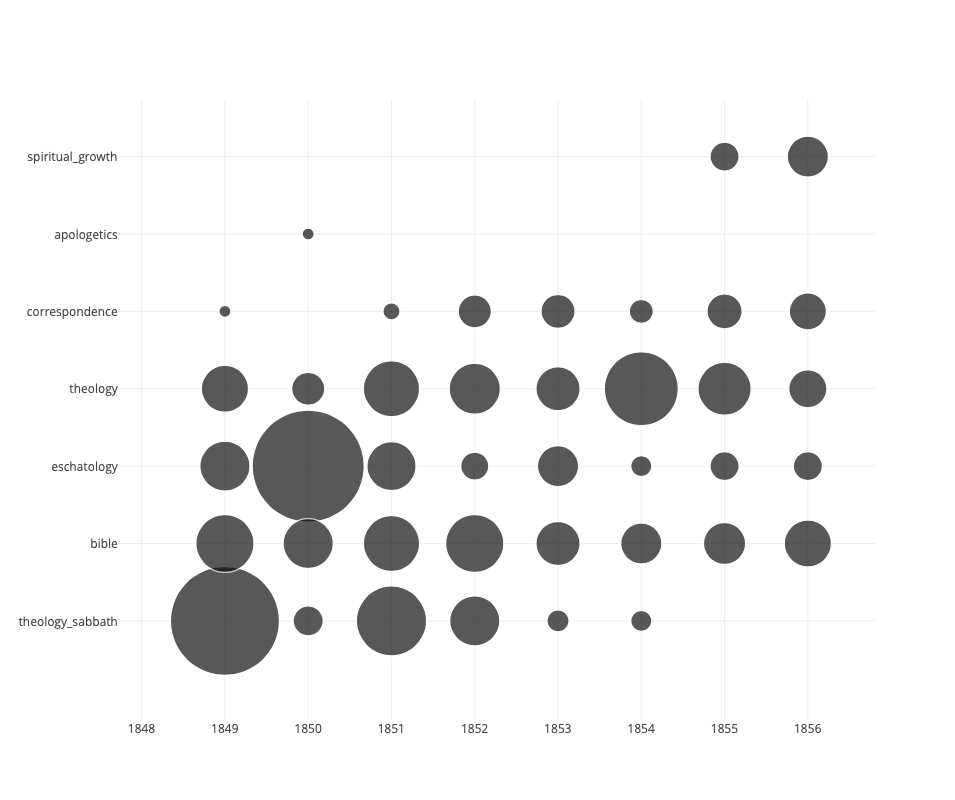

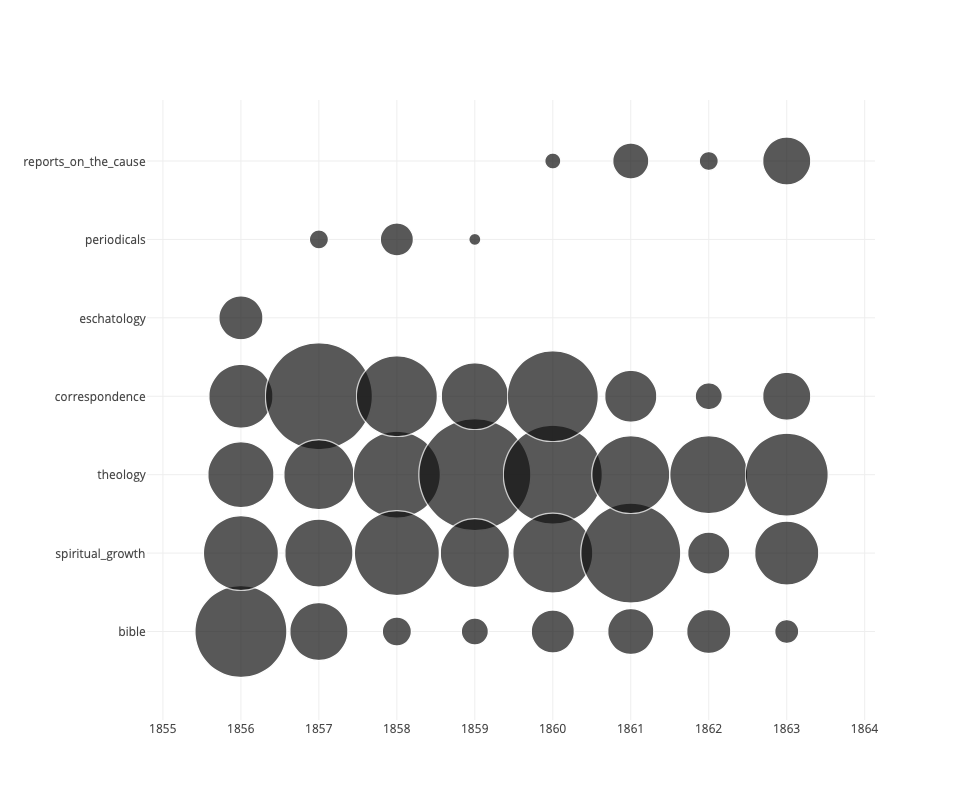

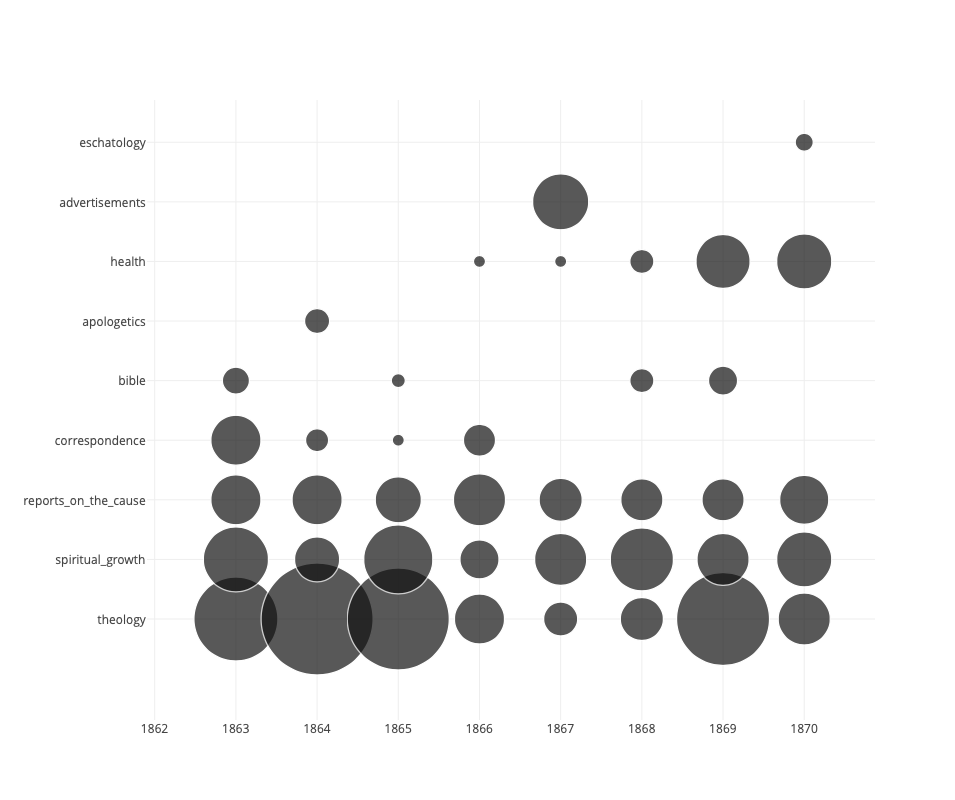

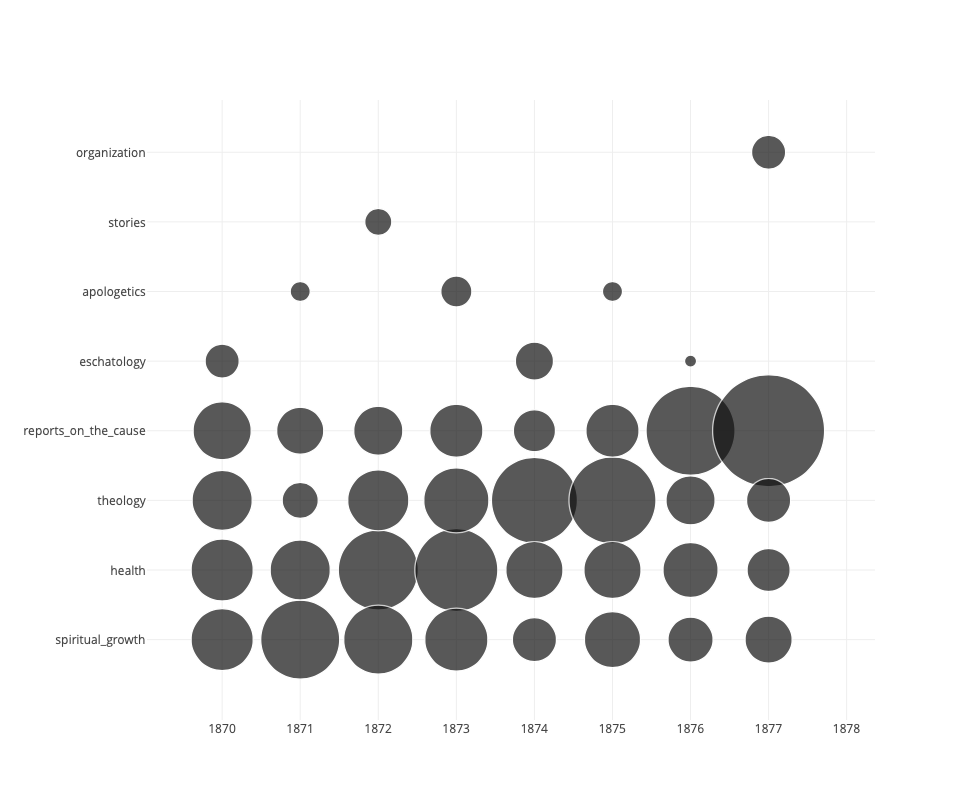

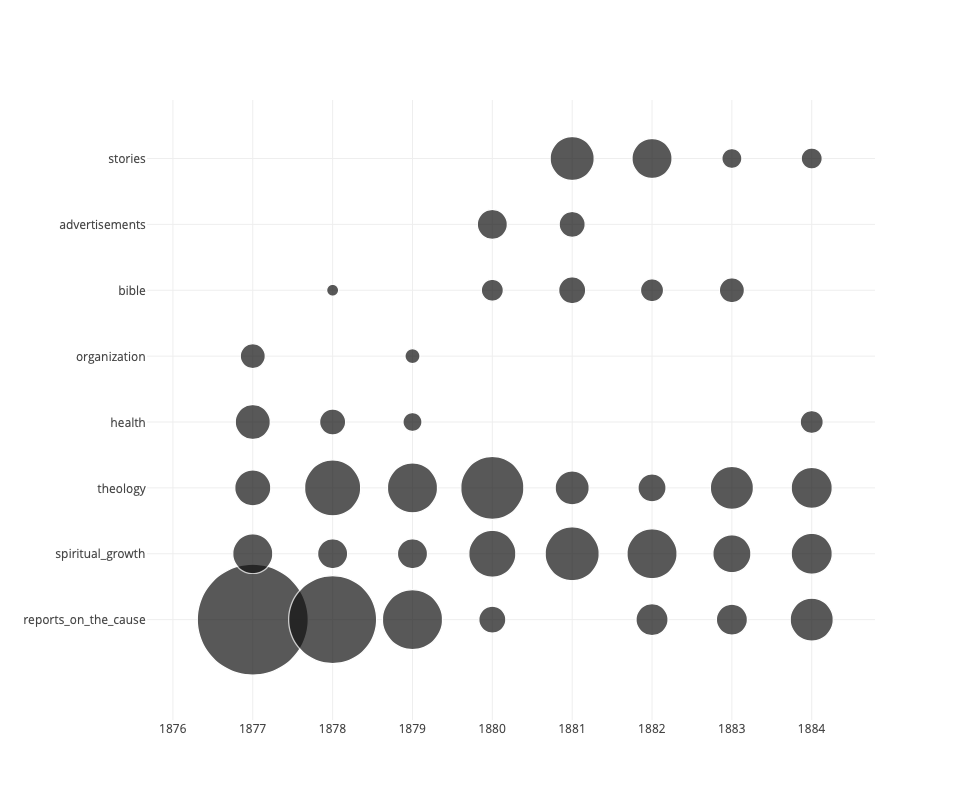

...

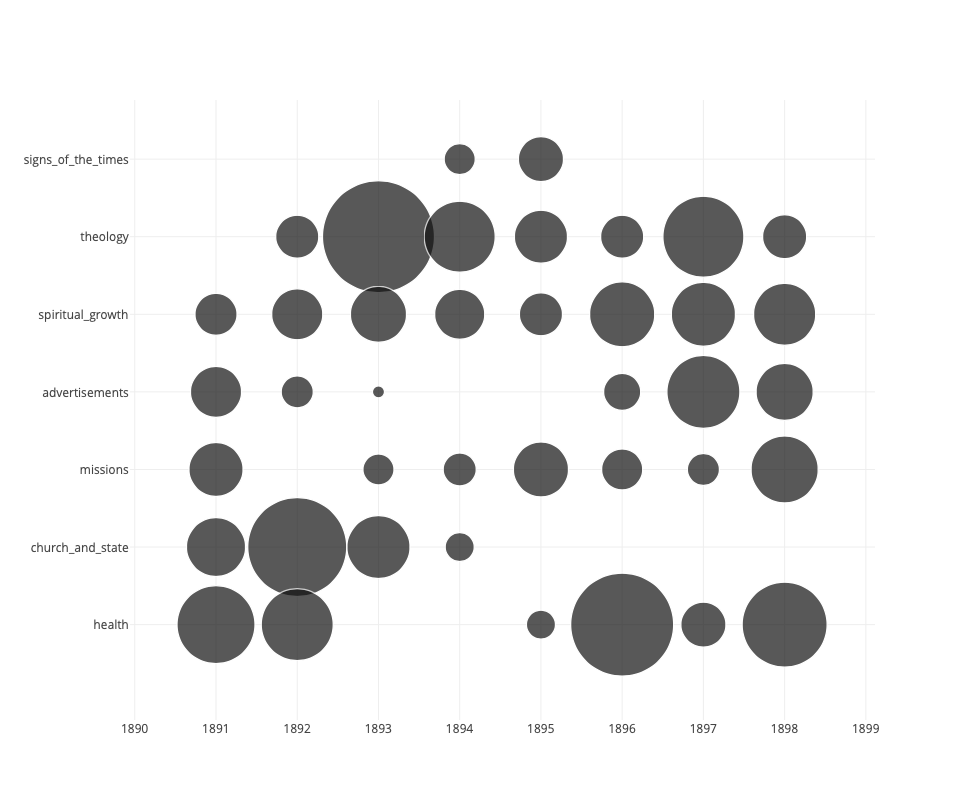

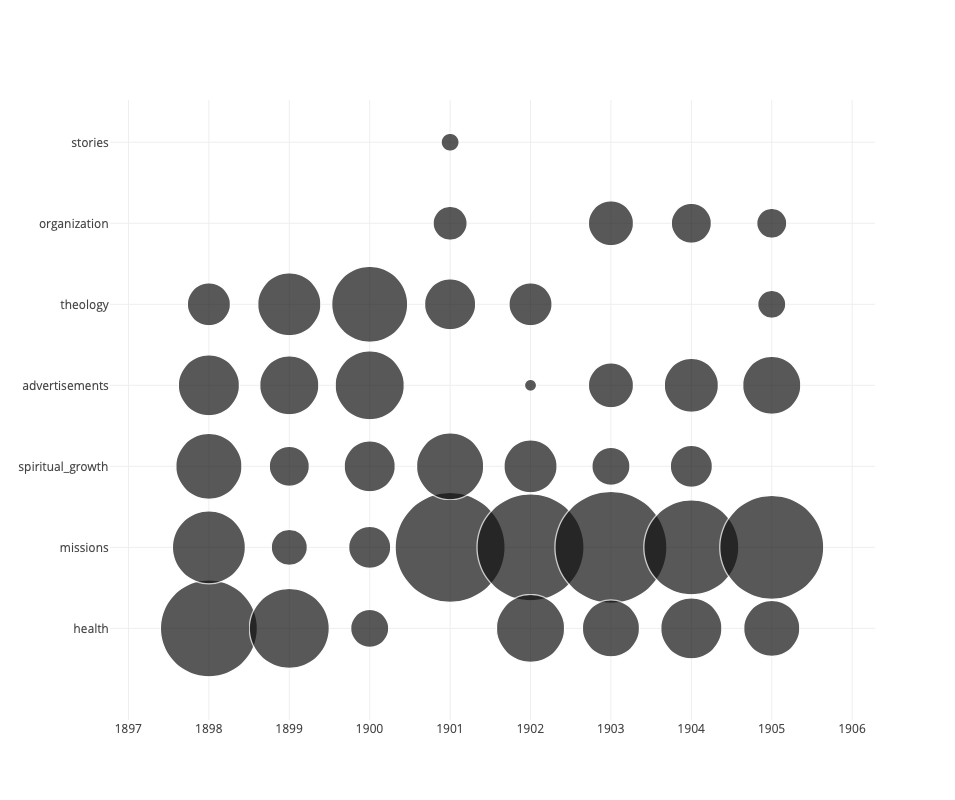

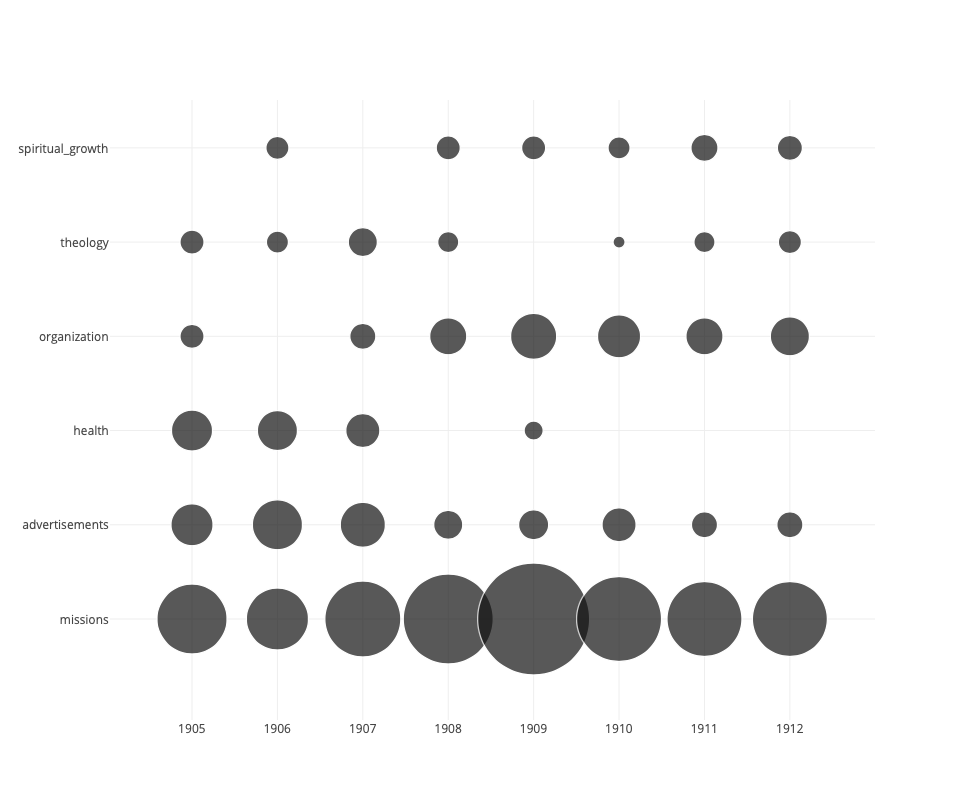

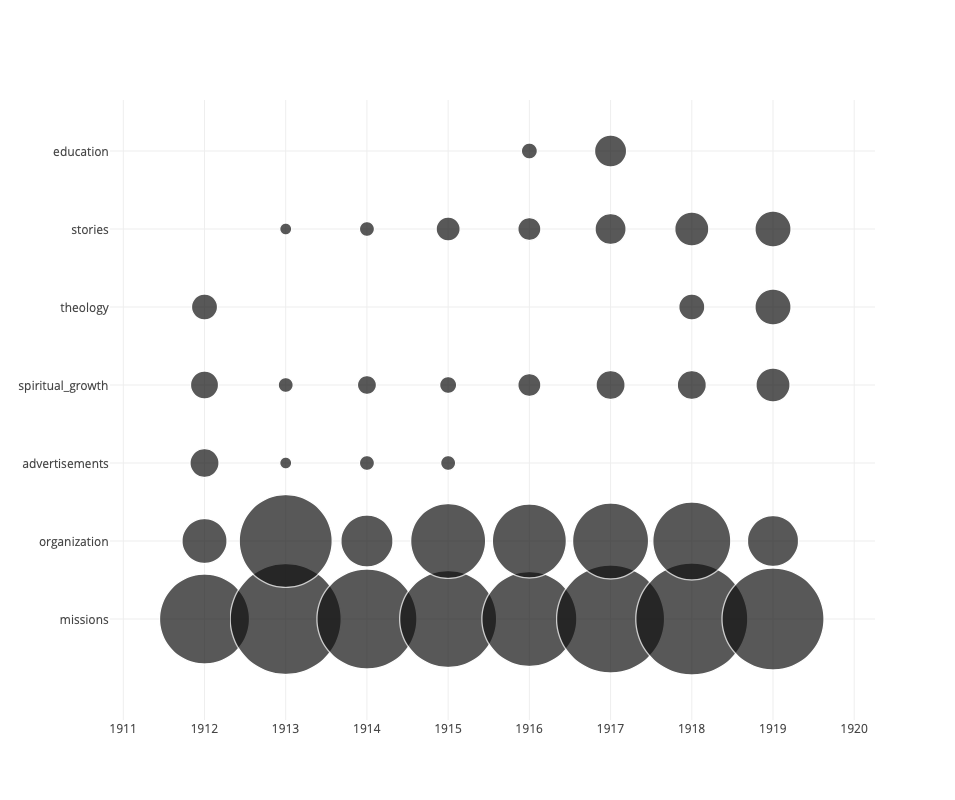

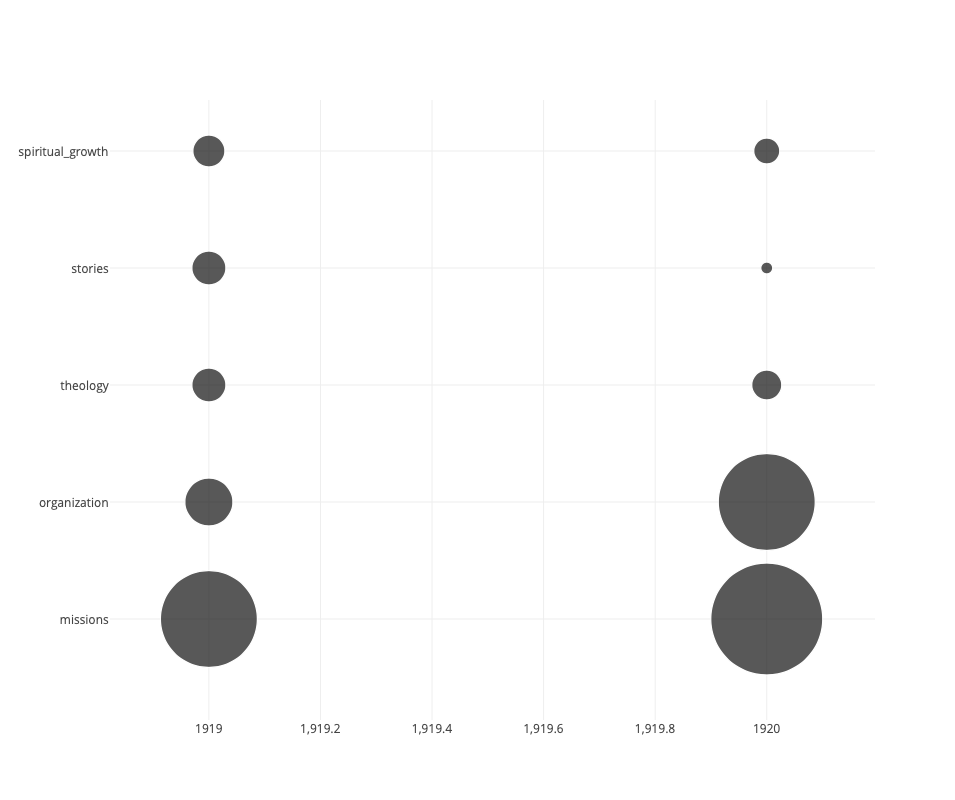

In [21]:
start_years = range(years[0], years[-1], 7)
for each in start_years:
    top_topics(each, each+7)

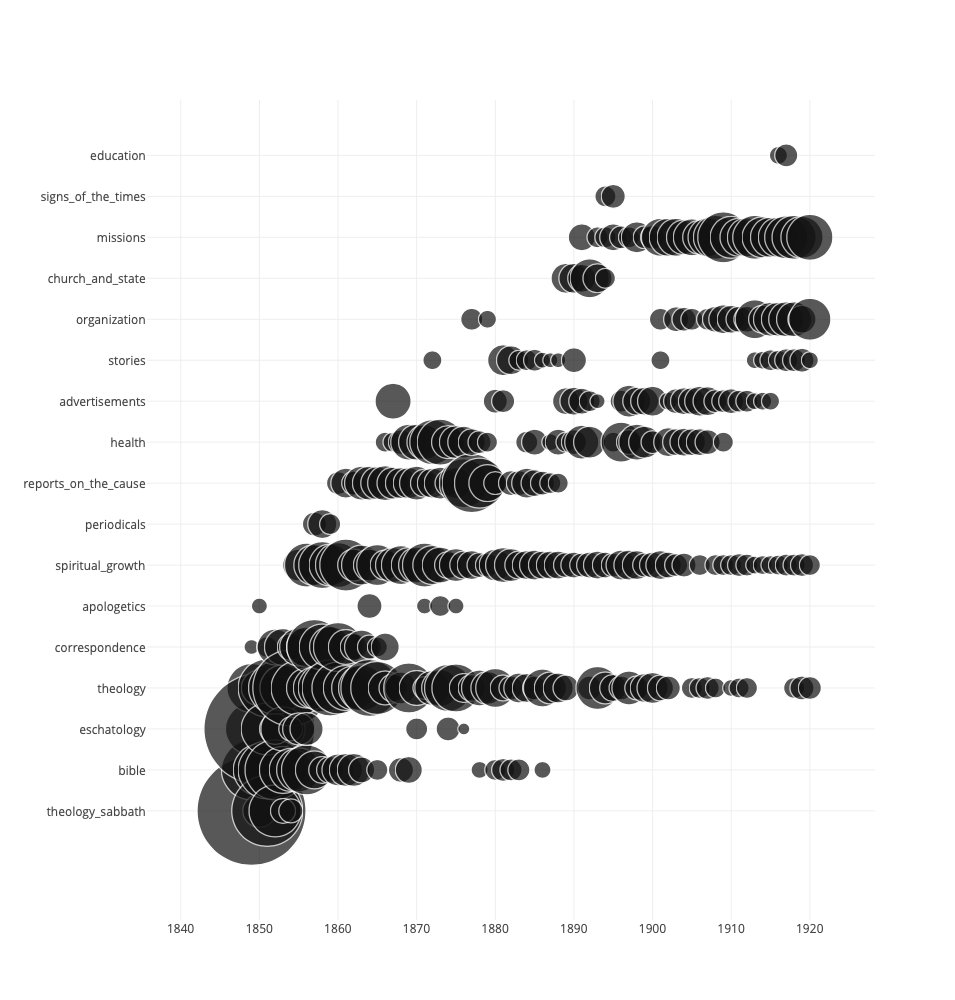

In [22]:
top_topics(start_year=1849, end_year=1920, height=1000)